<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_077_feature_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 77/365 — Feature Selection
## Do we really need every feature in a machine-learning model?

Feature Selection means keeping the useful features and removing those that add little value.

More features do not automatically mean a better model.

Too many irrelevant or redundant features can increase noise, training cost, overfitting risk, and pipeline complexity.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score


## 1. Load a real 30-feature dataset


In [2]:
data=load_breast_cancer(as_frame=True)
X=data.data
y=data.target

print("Dataset shape:",X.shape)
print("Number of features:",X.shape[1])


Dataset shape: (569, 30)
Number of features: 30


## 2. Baseline model with all features


In [3]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

baseline=Pipeline([
    ("scaler",StandardScaler()),
    ("model",LogisticRegression(max_iter=3000))
])

baseline.fit(X_train,y_train)
baseline_pred=baseline.predict(X_test)

baseline_accuracy=accuracy_score(
    y_test,
    baseline_pred
)

print("Accuracy with all features:",round(baseline_accuracy,3))


Accuracy with all features: 0.986


## 3. Select the top 10 features

`SelectKBest` scores each feature and keeps the strongest `K`.

Here we use `f_classif`, an ANOVA F-test score for classification.


In [4]:
selector=SelectKBest(
    score_func=f_classif,
    k=10
)

selector.fit(X_train,y_train)

selected_features=X.columns[
    selector.get_support()
]

print("Selected features:")
for feature in selected_features:
    print("-",feature)


Selected features:
- mean radius
- mean perimeter
- mean area
- mean concavity
- mean concave points
- worst radius
- worst perimeter
- worst area
- worst concavity
- worst concave points


## 4. Inspect the feature scores


In [5]:
feature_scores=pd.DataFrame({
    "Feature":X.columns,
    "Score":selector.scores_
}).sort_values(
    "Score",
    ascending=False
)

display(feature_scores.head(15).round(2))


,Feature,Score
27,worst concave points,736.82
7,mean concave points,675.65
22,worst perimeter,661.44
20,worst radius,634.14
2,mean perimeter,530.66
23,worst area,499.12
0,mean radius,491.37
3,mean area,441.36
6,mean concavity,389.92
26,worst concavity,339.35


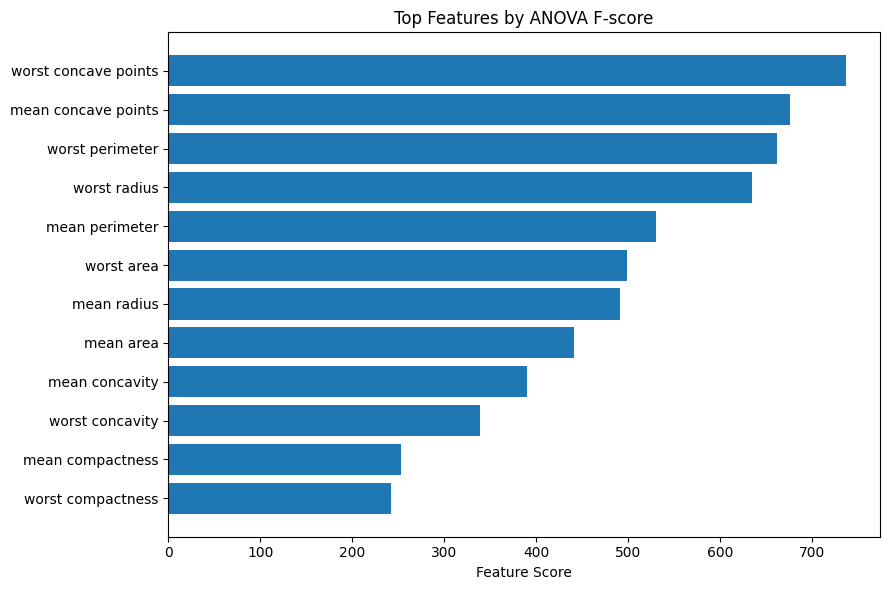

In [6]:
top_scores=feature_scores.head(12).sort_values("Score")

plt.figure(figsize=(9,6))
plt.barh(
    top_scores["Feature"],
    top_scores["Score"]
)
plt.xlabel("Feature Score")
plt.title("Top Features by ANOVA F-score")
plt.tight_layout()
plt.show()


## 5. Train using only selected features


In [7]:
selected_pipeline=Pipeline([
    ("selector",SelectKBest(
        score_func=f_classif,
        k=10
    )),
    ("scaler",StandardScaler()),
    ("model",LogisticRegression(max_iter=3000))
])

selected_pipeline.fit(
    X_train,
    y_train
)

selected_pred=selected_pipeline.predict(
    X_test
)

selected_accuracy=accuracy_score(
    y_test,
    selected_pred
)

print(
    "Accuracy with top 10 features:",
    round(selected_accuracy,3)
)


Accuracy with top 10 features: 0.951


## 6. Compare all features vs selected features


In [8]:
comparison=pd.DataFrame({
    "Model":[
        "All 30 Features",
        "Top 10 Features"
    ],
    "Number of Features":[
        X.shape[1],
        10
    ],
    "Test Accuracy":[
        baseline_accuracy,
        selected_accuracy
    ]
})

display(comparison.round(3))


,Model,Number of Features,Test Accuracy
0,All 30 Features,30,0.986
1,Top 10 Features,10,0.951


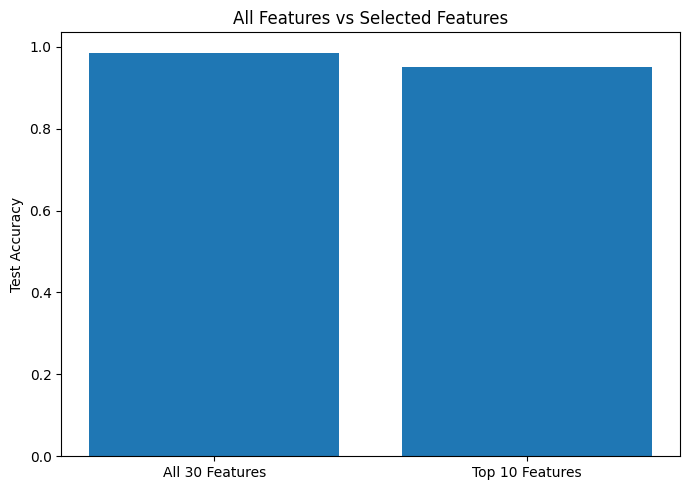

In [9]:
plt.figure(figsize=(7,5))
plt.bar(
    comparison["Model"],
    comparison["Test Accuracy"]
)
plt.ylabel("Test Accuracy")
plt.title("All Features vs Selected Features")
plt.tight_layout()
plt.show()


## 7. Three major feature-selection approaches

### Filter Methods
Use statistical tests before final model training.

Examples:
- correlation
- chi-square
- ANOVA F-test
- mutual information

### Wrapper Methods
Train models repeatedly on different feature subsets.

Example:
- Recursive Feature Elimination (RFE)

### Embedded Methods
Selection happens during model training.

Examples:
- L1 / Lasso
- Decision Tree feature importance
- Random Forest feature importance


## 8. Feature Selection vs PCA

### Feature Selection
Keeps original columns.

`30 original features → choose 10 original features`

### PCA
Creates new transformed features.

`30 original features → 5 principal components`

Feature selection usually preserves interpretability better.


## 9. Enterprise intuition

Suppose a production model starts with 500 features, but only 40 provide most of the useful signal.

Removing weak features may help:
- reduce feature-store cost
- reduce inference latency
- simplify upstream pipelines
- improve interpretability
- reduce fragile data dependencies

A weak feature that requires an expensive data pipeline may simply not be worth keeping.


## 10. Leakage warning

Feature selection must be learned only from training data.

Doing feature selection on the full dataset before train/test split can leak test-set information.

The safer pattern is:

`Training Data → Feature Selection → Model`

Use a Pipeline during cross-validation.


## What does this teach?

- More features do not automatically improve a model.
- Feature selection removes irrelevant or redundant inputs.
- Filter, wrapper and embedded methods are major approaches.
- SelectKBest is a simple filter method.
- Feature selection preserves original features.
- PCA creates new transformed features.
- Feature selection must stay inside the training workflow.

> **A good ML model is not the one with the most features. It is the one using features that actually add useful signal.**


## References

- https://scikit-learn.org/stable/modules/feature_selection.html
- https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html
- https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html
- https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
